# 03 – Feature engineering, model training and evaluation

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/books_clean.csv")
y = df["is_fiction"]  # what we want to predict: 1 = Fiction, 0 = Nonfiction
print(df.shape)

(174, 11)


## 1. Feature engineering

Four groups of features, based on what the analysis in notebook 02 showed:

| Group | Features | Expectation |
|---|---|---|
| Text | TF-IDF of title + description | Strongest signal |
| Title patterns | has colon, has series "#", number of words | Strong, found in the analysis |
| Cover colours | Colour histogram of the image | Probably weak |
| Price, rating, stock | As scraped | No signal, they are random on this site |

### Text
Title and description are joined into one text. TF-IDF turns each text into a vector with one
value per word: words that are frequent in this book but rare across all books get a high value.
The vectorizer itself is created inside the model below, so it only learns from the training data.

In [2]:
# one big text per book, the title words count too
df["text"] = df["title"] + " " + df["description"]

### Title patterns

In [3]:
# True/False -> 1/0 so the model can use them
df["title_has_colon"] = df["title"].str.contains(":").astype(int)
df["title_has_series"] = df["title"].str.contains("#").astype(int)
df["title_words"] = df["title"].str.split().str.len()

### Cover colours
Each cover is described by how much of each colour it contains: 8 brightness bins per colour
channel (red, green, blue), so 24 numbers per book. Each histogram is divided by the number of
pixels, so the different image sizes don't matter and no resizing is needed.

In [4]:
def colour_histogram(path, bins=8):
    # turn the image into a grid of pixels: height x width x 3 colours
    img = np.array(Image.open(path).convert("RGB"))
    hist = []
    for channel in range(3):  # 0 = red, 1 = green, 2 = blue
        # img[:, :, channel] = all pixels of one color counted into 8 brightness buckets
        counts, _ = np.histogram(img[:, :, channel], bins=bins, range=(0, 256))
        hist.extend(counts / counts.sum())  # share of pixels, so image size doesnt matter
    return hist


COLOUR_COLS = [f"{c}{i}" for c in "rgb" for i in range(8)]  # column names r0..r7, g0..g7, b0..b7
colours = pd.DataFrame([colour_histogram(p) for p in df["image_path"]], columns=COLOUR_COLS)
df = pd.concat([df, colours], axis=1)  # stick the 24 colour columns onto df
df[COLOUR_COLS].head(3).round(2)

,r0,r1,r2,r3,r4,r5,r6,r7,g0,g1,...,g6,g7,b0,b1,b2,b3,b4,b5,b6,b7
0,0.21,0.12,0.04,0.04,0.07,0.07,0.11,0.34,0.35,0.09,...,0.03,0.28,0.29,0.16,0.06,0.05,0.10,0.03,0.03,0.27
1,0.74,0.08,0.02,0.02,0.02,0.04,0.03,0.05,0.00,0.04,...,0.04,0.08,0.02,0.53,0.31,0.04,0.02,0.02,0.02,0.04
2,0.92,0.03,0.01,0.01,0.00,0.00,0.01,0.01,0.93,0.02,...,0.00,0.00,0.95,0.03,0.02,0.01,0.00,0.00,0.00,0.00


## 2. Model and evaluation setup

**Model: Logistic Regression.** It is simple, fast, works well with TF-IDF text features, and its
weights show which words point towards Fiction or Nonfiction.

- `class_weight="balanced"` gives the smaller Fiction class more weight, so the model doesnt just learn to say "Nonfiction".
- Numeric features are scaled with `StandardScaler`, so features with big values (price) don't dominate small ones (colour shares).
- Everything is put in one `Pipeline`, so the TF-IDF and scaler are fitted on the training folds only (no information leaks from the test fold).

**Evaluation: stratified 5-fold cross-validation.** With only 174 books, a single train/test split
would be very dependent on which books end up in the test set. Cross-validation tests on every book
exactly once. "Stratified" keeps the Fiction/Nonfiction ratio the same in every fold.

Metrics: **accuracy**, and **F1 for Fiction**, since accuracy alone looks good even for a model that
always says "Nonfiction" (63%). Each score is shown with its **standard deviation** over the 5 folds:
with only ~35 books per test fold, scores move a few percent depending on the split, so small
differences between models shouldn't be over-interpreted.

In [5]:
def make_model(use_text=False, num_cols=(), C=1):
    # pick which columns go into the model and how each one is prepared
    parts = []
    if use_text:
        parts.append(("text", TfidfVectorizer(stop_words="english"), "text"))  # words -> numbers
    if num_cols:
        parts.append(("num", StandardScaler(), list(num_cols)))  # put numbers on the same scale
    return Pipeline([
        ("features", ColumnTransformer(parts)),
        # balanced = give the smaller Fiction class more weight, max_iter = give it enough time to finish
        ("clf", LogisticRegression(C=C, class_weight="balanced", max_iter=1000)),
    ])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)  # fixed seed so results are repeatable

def evaluate(model):
    # trains and tests 5 times, each time on a different fold, then we take the average
    scores = cross_validate(model, df, y, cv=cv, scoring=["accuracy", "f1"])
    # mean = the score, std = how much it jumps around between the 5 folds
    return (scores["test_accuracy"].mean(), scores["test_accuracy"].std(),
            scores["test_f1"].mean(), scores["test_f1"].std())

## 3. Choose the regularisation strength C

`C` controls how much the model is allowed to trust its features: a small C keeps the weights
small (simpler model, less overfitting), a large C lets them grow. With the default `C=1`, the
thousands of small TF-IDF weights are held back so much that the 3 title features dominate when
they are combined. A few values are tried on the text + title model.

In [6]:
# column groups, so we can mix and match them below
NUMERIC_COLS = ["price", "rating", "stock"]
TITLE_COLS = ["title_has_colon", "title_has_series", "title_words"]

# try a few values on the text + title model and see which scores best
for C in [0.1, 1, 10, 100]:
    acc, acc_std, f1, f1_std = evaluate(make_model(use_text=True, num_cols=TITLE_COLS, C=C))
    # {C:<5} pads the number so the columns line up, {:.3f} shows 3 decimals
    print(f"C={C:<5} accuracy={acc:.3f} ± {acc_std:.3f}  f1_fiction={f1:.3f} ± {f1_std:.3f}")

C=0.1   accuracy=0.822 ± 0.052  f1_fiction=0.805 ± 0.051
C=1     accuracy=0.833 ± 0.058  f1_fiction=0.816 ± 0.059
C=10    accuracy=0.851 ± 0.038  f1_fiction=0.826 ± 0.039
C=100   accuracy=0.856 ± 0.017  f1_fiction=0.825 ± 0.022


`C=10` and `C=100` score about the same (the difference is far smaller than the ± spread), and both beat `C=1`. `C=10` is used from here on, as the smaller of the two: less freedom for the model means less risk of overfitting. (Note: C is chosen with the same
cross-validation that is used to report results, so the scores may be slightly optimistic.)

## 4. Compare feature sets

Each feature group is tested on its own first, then combined. This shows which features actually help.

In [7]:
C = 10  # the winner from the test above

# one model per feature set, the dummy one just always guesses the most common class
models = {
    "Baseline (always Nonfiction)": DummyClassifier(strategy="most_frequent"),
    "Price, rating, stock": make_model(num_cols=NUMERIC_COLS, C=C),
    "Cover colours": make_model(num_cols=COLOUR_COLS, C=C),
    "Title patterns": make_model(num_cols=TITLE_COLS, C=C),
    "Text (TF-IDF)": make_model(use_text=True, C=C),
    "Text + title patterns": make_model(use_text=True, num_cols=TITLE_COLS, C=C),
    "All features": make_model(use_text=True, num_cols=TITLE_COLS + COLOUR_COLS + NUMERIC_COLS, C=C),
}

# run cross-validation on each model and collect the scores
results = []
for name, model in models.items():
    acc, acc_std, f1, f1_std = evaluate(model)
    results.append({"features": name, "accuracy": acc, "accuracy_std": acc_std,
                    "f1_fiction": f1, "f1_std": f1_std})

results = pd.DataFrame(results).round(3)  # list of dicts -> table, 3 decimals
results

,features,accuracy,accuracy_std,f1_fiction,f1_std
0,Baseline (always Nonfiction),0.632,0.007,0.000,0.000
1,"Price, rating, stock",0.506,0.073,0.404,0.085
2,Cover colours,0.586,0.051,0.461,0.101
3,Title patterns,0.828,0.060,0.805,0.066
4,Text (TF-IDF),0.868,0.043,0.789,0.090
5,Text + title patterns,0.851,0.038,0.826,0.039
6,All features,0.787,0.030,0.722,0.054


## 5. Final model: a closer look

The best feature set from the table is examined in more detail. `cross_val_predict` gives a
prediction for every book from the fold where it was in the test set, so these are honest
predictions on unseen data.

In [8]:
final_model = make_model(use_text=True, num_cols=TITLE_COLS, C=C)
# every book gets predicted onceD by a model that never saw it during training
pred = cross_val_predict(final_model, df, y, cv=cv)

# precision, recall and f1 for each class
print(classification_report(y, pred, target_names=["Nonfiction", "Fiction"]))

              precision    recall  f1-score   support

  Nonfiction       0.97      0.79      0.87       110
     Fiction       0.73      0.95      0.82        64

    accuracy                           0.85       174
   macro avg       0.85      0.87      0.85       174
weighted avg       0.88      0.85      0.85       174



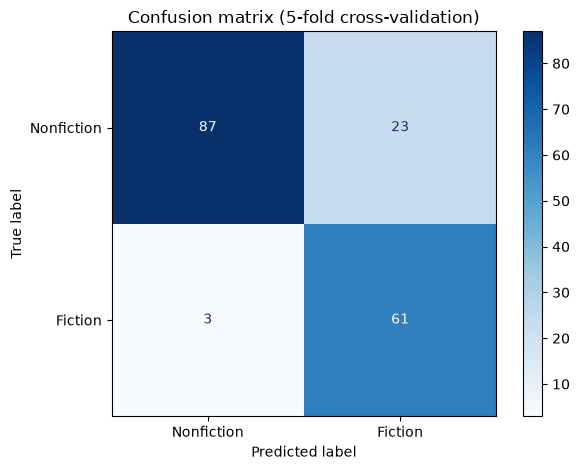

In [9]:
# rows = real category, columns = what the model guessed
ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=["Nonfiction", "Fiction"], cmap="Blues")
plt.title("Confusion matrix (5-fold cross-validation)")
plt.tight_layout()
plt.savefig("figures/confusion_matrix.png", dpi=150)  # saved for the report
plt.show()

### Which books are misclassified?

In [10]:
# keep only the rows where the prediction doesnt match the real category
wrong = df[pred != y][["title", "category"]]
print(len(wrong), "of", len(df), "books misclassified")
wrong

26 of 174 books misclassified


,title,category
6,The Regional Office Is Under Attack!,Fiction
12,Still Life with Bread Crumbs,Fiction
34,Hystopia: A Novel,Fiction
66,Reasons to Stay Alive,Nonfiction
81,The Genius of Birds,Nonfiction
83,So You've Been Publicly Shamed,Nonfiction
102,Abstract City,Nonfiction
109,"Mother, Can You Not?",Nonfiction
114,Why Not Me?,Nonfiction
118,Rising Strong,Nonfiction


### What did the model learn?
The model is fitted once on all books, then the weights are inspected. A positive weight pushes
towards Fiction, a negative weight towards Nonfiction.

In [11]:
final_model.fit(df, y)  # this time train on all books just to look at the weigts

# grab the feature names and the matching weights from inside the pipeline
names = final_model.named_steps["features"].get_feature_names_out()
# coef_ = one weight per feature, positive means Fiction, negative means Nonfiction
weights = pd.Series(final_model.named_steps["clf"].coef_[0], index=names)
weights.index = weights.index.str.replace("text__", "").str.replace("num__", "")  # drop the prefixes

# the 15 strongest words/features in each direction
pd.DataFrame({
    "Fiction": weights.nlargest(15).index,
    "Nonfiction": weights.nsmallest(15).index,
})

,Fiction,Nonfiction
0,novel,title_words
1,love,title_has_colon
2,lucy,kate
3,regional,classics
4,title_has_series,penny
5,family,brave
6,means,wiesel
7,jane,birds
8,secret,gratitude
9,hystopia,readers
